# Reanalysis of "ZNF512B protects critical regulatory regions to safeguard long term genomic integrity"

Here, I will analyse RNA-seq data from the paper "ZNF512B protects critical regulatory regions to safeguard long term genomic integrity". ZNF512B safeguards genome integrity at key regulatory regions, and its activity prevents senescence and inflammation-associated gene expression. Here, I will be focusing on the determination of senescence-associated gene expression profiles.

## Load Counts

I will use raw counts obtained using the Rsubread package in R (featureCounts) from the FASTP -> HISAT2 pipeline, which will be used for downstream analysis with DESeq2.

In [23]:
import os

In [24]:
os.getcwd()

'C:\\Users\\cdsou\\Desktop\\GSE206071'

In [25]:
import pandas as pd
import numpy as np

In [26]:
pd.__version__

'2.3.3'

In [27]:
raw_counts = pd.read_csv('output_data/feature_counts/raw_counts.tsv', sep = '\t', index_col = 0)
raw_counts

,siZNF512B_R2,siZNF512B_R1,siControl_R2,siControl_R1
gene_symbol,,,,
DDX11L1,18,21,8,32
WASH7P,3287,3340,2748,4437
MIR6859-1,64,65,17,110
MIR1302-2,0,0,0,0
FAM138A,1,1,7,14
...,...,...,...,...
LOC102723382,0,0,0,0
LOC642249,0,0,0,0
LOC105379554,0,0,0,0


I will also create a metadata table:

In [28]:
d = {"Treatment": ["siZNF512B", "siZNF512B", "Control", "Control"], "Cell Type": ["Fibroblast", "Fibroblast", "Fibroblast", "Fibroblast"]}
sample_metadata = pd.DataFrame(data=d)
sample_metadata

,Treatment,Cell Type
0,siZNF512B,Fibroblast
1,siZNF512B,Fibroblast
2,Control,Fibroblast
3,Control,Fibroblast


In [29]:
sample_metadata.index = raw_counts.columns
sample_metadata

,Treatment,Cell Type
siZNF512B_R2,siZNF512B,Fibroblast
siZNF512B_R1,siZNF512B,Fibroblast
siControl_R2,Control,Fibroblast
siControl_R1,Control,Fibroblast


Raw counts need to be transposed:

In [30]:
raw_counts_t = raw_counts.T
raw_counts_t

gene_symbol,DDX11L1,WASH7P,MIR6859-1,MIR1302-2,FAM138A,OR4F5,LOC729737,DDX11L17,LOC102723897,MIR6859-2,...,LOC100507412,RNA45SN5,RNA18SN5,RNA5-8SN5,RNA28SN5,LOC102723382,LOC642249,LOC105379554,LOC105379557,LOC105379561
siZNF512B_R2,18,3287,64,0,1,0,695,11,2542,64,...,0,0,0,0,0,0,0,0,0,0
siZNF512B_R1,21,3340,65,0,1,0,646,11,2591,65,...,0,0,0,0,0,0,0,0,0,0
siControl_R2,8,2748,17,0,7,0,450,2,1976,17,...,0,0,0,0,0,0,0,0,0,0
siControl_R1,32,4437,110,0,14,0,813,22,3364,110,...,0,0,0,0,0,0,0,0,0,0


In [31]:
raw_counts_t.index == sample_metadata.index

array([ True,  True,  True,  True])

Filter genes with low expression, as recommended for DESeq2 analysis:

In [32]:
min_count = 10

In [33]:
(raw_counts_t > min_count).sum()

gene_symbol
DDX11L1         3
WASH7P          4
MIR6859-1       4
MIR1302-2       0
FAM138A         1
               ..
LOC102723382    0
LOC642249       0
LOC105379554    0
LOC105379557    0
LOC105379561    0
Length: 27771, dtype: int64

In [34]:
genes_to_keep = (raw_counts_t > min_count).sum() > 1
genes_to_keep

gene_symbol
DDX11L1          True
WASH7P           True
MIR6859-1        True
MIR1302-2       False
FAM138A         False
                ...  
LOC102723382    False
LOC642249       False
LOC105379554    False
LOC105379557    False
LOC105379561    False
Length: 27771, dtype: bool

In [35]:
raw_counts_t_filtered = raw_counts_t.loc[:, genes_to_keep]
raw_counts_t_filtered

gene_symbol,DDX11L1,WASH7P,MIR6859-1,LOC729737,DDX11L17,LOC102723897,MIR6859-2,LOC100132287,LOC105378947,LOC100288069,...,SPRY3,VAMP7,DDX11L16,ZFY,PCDH11Y,TBL1Y,PRKY,DDX3Y,GOLGA2P2Y,GOLGA2P3Y
siZNF512B_R2,18,3287,64,695,11,2542,64,709,22,159,...,282,2956,126,49,17,17,83,114,36,36
siZNF512B_R1,21,3340,65,646,11,2591,65,666,13,136,...,299,2985,152,54,19,16,103,115,47,40
siControl_R2,8,2748,17,450,2,1976,17,517,14,85,...,125,3352,98,28,16,25,91,135,27,25
siControl_R1,32,4437,110,813,22,3364,110,839,14,171,...,128,3584,226,37,12,28,109,81,58,42


## DESeq2 Results

In [36]:
import pickle as pkl
from pydeseq2.dds import DeseqDataSet
from pydeseq2.default_inference import DefaultInference
from pydeseq2.ds import DeseqStats
from pydeseq2.utils import load_example_data

In [37]:
sample_metadata

,Treatment,Cell Type
siZNF512B_R2,siZNF512B,Fibroblast
siZNF512B_R1,siZNF512B,Fibroblast
siControl_R2,Control,Fibroblast
siControl_R1,Control,Fibroblast


In [38]:
inference = DefaultInference(n_cpus=8)
dds = DeseqDataSet(
    counts = raw_counts_t_filtered,
    metadata = sample_metadata,
    design = "~Treatment",
    refit_cooks = True,
    inference = inference,
)

In [39]:
dds.deseq2()

Fitting size factors...
... done in 0.00 seconds.



Using None as control genes, passed at DeseqDataSet initialization


Fitting dispersions...
... done in 2.77 seconds.

Fitting dispersion trend curve...
... done in 0.42 seconds.

C:\Users\cdsou\miniconda3\envs\bioinformatic_analyses\Lib\site-packages\pydeseq2\dds.py:548: UserWarning: As the residual degrees of freedom is less than 3, the distribution of log dispersions is especially asymmetric and likely to be poorly estimated by the MAD.
  self.fit_dispersion_prior()
Fitting MAP dispersions...
... done in 2.98 seconds.

Fitting LFCs...
... done in 1.86 seconds.

Calculating cook's distance...
... done in 0.01 seconds.

Replacing 0 outlier genes.



In [46]:
deseq2_results = DeseqStats(dds, contrast = ["Treatment", "siZNF512B", "Control"], inference = inference, cooks_filter = False, independent_filter = False)

Note: I usually turn off Cook's Cutoff to not exclude potential outliers (they can be extracted later, and for GSEA they don't affect much) and turn off Independent Filtering, because low abundance genes were already filtered manually by me in the previous steps.

In [47]:
deseq2_results.summary()

Running Wald tests...


Log2 fold change & Wald test p-value: Treatment siZNF512B vs Control
                baseMean  log2FoldChange     lfcSE      stat    pvalue  \
gene_symbol                                                              
DDX11L1        19.498050       -0.155375  0.945740 -0.164289  0.869504   
WASH7P       3435.317989       -0.247786  0.217835 -1.137493  0.255332   
MIR6859-1      63.024818       -0.088333  0.686112 -0.128744  0.897561   
LOC729737     645.260498       -0.041925  0.273870 -0.153082  0.878333   
DDX11L17       11.327646       -0.233433  1.272660 -0.183421  0.854468   
...                  ...             ...       ...       ...       ...   
TBL1Y          21.656303       -0.822074  0.829731 -0.990772  0.321797   
PRKY           96.162457       -0.244231  0.424392 -0.575485  0.564963   
DDX3Y         111.177658       -0.066943  0.430088 -0.155650  0.876309   
GOLGA2P2Y      41.609278       -0.163493  0.646966 -0.252708  0.800494   
GOLGA2P3Y      35.379545        0.049482  0

... done in 1.36 seconds.



In [48]:
deseq2_results = deseq2_results.results_df.sort_values("padj")
deseq2_results

,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
gene_symbol,,,,,,
PTGS2,1944.284950,4.959952,0.224000,22.142663,1.227641e-108,1.881973e-104
CXCL2,2807.347907,6.664353,0.306031,21.776690,3.859685e-105,2.958448e-101
SCG2,3411.094591,4.946704,0.236794,20.890309,6.559322e-97,3.351813e-93
C3,4733.534935,5.469138,0.266609,20.513739,1.623230e-93,6.221028e-90
G0S2,1134.537165,5.477980,0.287761,19.036569,8.491044e-81,2.603354e-77
...,...,...,...,...,...,...
ANO7,113.619027,0.000341,0.395916,0.000861,9.993131e-01,9.995739e-01
RNF19B,707.703648,-0.000179,0.230984,-0.000776,9.993806e-01,9.995762e-01
HMG20A,1591.321940,0.000100,0.188299,0.000529,9.995781e-01,9.997085e-01


We can already see that top upregulated genes are related to inflammation. Let's save the results:

In [50]:
os.makedirs("output_data/deseq2_results", exist_ok=True)

In [51]:
deseq2_results.to_csv("output_data/deseq2_results/siZNF512B_vs_Control_DESeq2_Results.csv")

Let's check some genes of interest:

In [52]:
deseq2_results.loc[["FOXM1", "KIF2C", "LMNB1", "MKI67", "IL6", "CXCL8", "BDKRB2", "IGFBP2", "IL17RB", "CDKN2A", "CDKN1A", "MDM2", "CDKN2B"]]

,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
gene_symbol,,,,,,
FOXM1,756.644517,-2.470136,0.268362,-9.204488,3.433041e-20,4.278742e-18
KIF2C,359.599236,-2.446108,0.354223,-6.905568,5.000310e-12,2.147192e-10
LMNB1,666.655747,-2.267138,0.248305,-9.130447,6.821724e-20,8.299765e-18
MKI67,1614.178011,-2.580206,0.321181,-8.033493,9.473644e-16,6.948850e-14
IL6,15020.940162,5.920639,0.728625,8.125767,4.445438e-16,3.390476e-14
CXCL8,50953.639684,7.811224,0.746593,10.462492,1.284326e-25,2.660638e-23
BDKRB2,17685.566807,1.030160,0.287453,3.583748,3.386984e-04,2.761833e-03
IGFBP2,3424.290617,0.725150,0.318526,2.276577,2.281148e-02,8.813002e-02
IL17RB,43.295694,0.145898,0.602465,0.242168,8.086500e-01,9.173157e-01


It's quite curious that p53 targets such as CDKN1A and MDM2 are not upregulated, as well as CDKN2A, despite the authors observing DNA damage and the strong SASP response. Let's check ZNF512B counts:

In [68]:
deseq2_results.loc[["ZNF512B", "ZNF512"]]

,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
gene_symbol,,,,,,
ZNF512B,1404.917338,-1.973760,0.192771,-10.238892,1.327473e-24,2.608995e-22
ZNF512,1602.343372,0.082833,0.202576,0.408899,6.826140e-01,8.467087e-01


Let's create a volcano plot:

In [98]:
from lets_plot import *
LetsPlot.setup_html()

# --- Parameters ---
padj_cut = 0.05
lfc_cut = 1

genes_to_label = [
    "ZNF512B",                                   # the knockdown target
    "CXCL8", "IL6", "CSF3", "CCL20",             # SASP / inflammation
    "CXCL2", "C3", "TNF",
]

# --- Prepare data ---
volcano_df = deseq2_results.copy().reset_index()   # gene_symbol becomes a column
volcano_df = volcano_df.dropna(subset=["padj"])

# Guard against padj == 0 (would give inf on the y-axis)
min_nonzero = volcano_df.loc[volcano_df["padj"] > 0, "padj"].min()
volcano_df["neglog10padj"] = -np.log10(volcano_df["padj"].clip(lower=min_nonzero))

volcano_df["category"] = np.select(
    [
        (volcano_df["padj"] < padj_cut) & (volcano_df["log2FoldChange"] >  lfc_cut),
        (volcano_df["padj"] < padj_cut) & (volcano_df["log2FoldChange"] < -lfc_cut),
    ],
    ["Up", "Down"],
    default="NS",
)

n_up = (volcano_df["category"] == "Up").sum()
n_down = (volcano_df["category"] == "Down").sum()

label_df = volcano_df[volcano_df["gene_symbol"].isin(genes_to_label)]

# --- Plot ---
volcano_plot = (
    ggplot(volcano_df, aes(x="log2FoldChange", y="neglog10padj"))
    + geom_point(aes(color="category"), size=1.5, alpha=0.6)
    + geom_point(data=label_df, color="black", shape=21, size=2.5)   # outline labelled genes
    + geom_text(
        data=label_df,
        mapping=aes(label="gene_symbol"),
        size=7, nudge_y=4, check_overlap=True,
    )
+ geom_vline(xintercept=-lfc_cut, linetype="dashed", color="grey")
+ geom_vline(xintercept=lfc_cut, linetype="dashed", color="grey")
    + scale_color_manual(
        values=["#2c7bb6", "#bdbdbd", "#d7191c"],
        breaks=["Down", "NS", "Up"],
        name="Direction",
    )
    + labs(
        x="log2 fold change (siZNF512B vs Control)",
        y="-log10(adjusted p-value)",
        title="siZNF512B vs Control",
        subtitle=f"Up: {n_up} | Down: {n_down} (padj < {padj_cut}, |log2FC| > {lfc_cut})",
    )
    + theme_bw()
    + ggsize(700, 550)
)

volcano_plot
ggsave(volcano_plot, "output_data/gsea_results/siZNF512B_volcano_plot_plot.png", path=".")

'C:\\Users\\cdsou\\Desktop\\GSE206071\\output_data\\gsea_results\\siZNF512B_volcano_plot_plot.png'

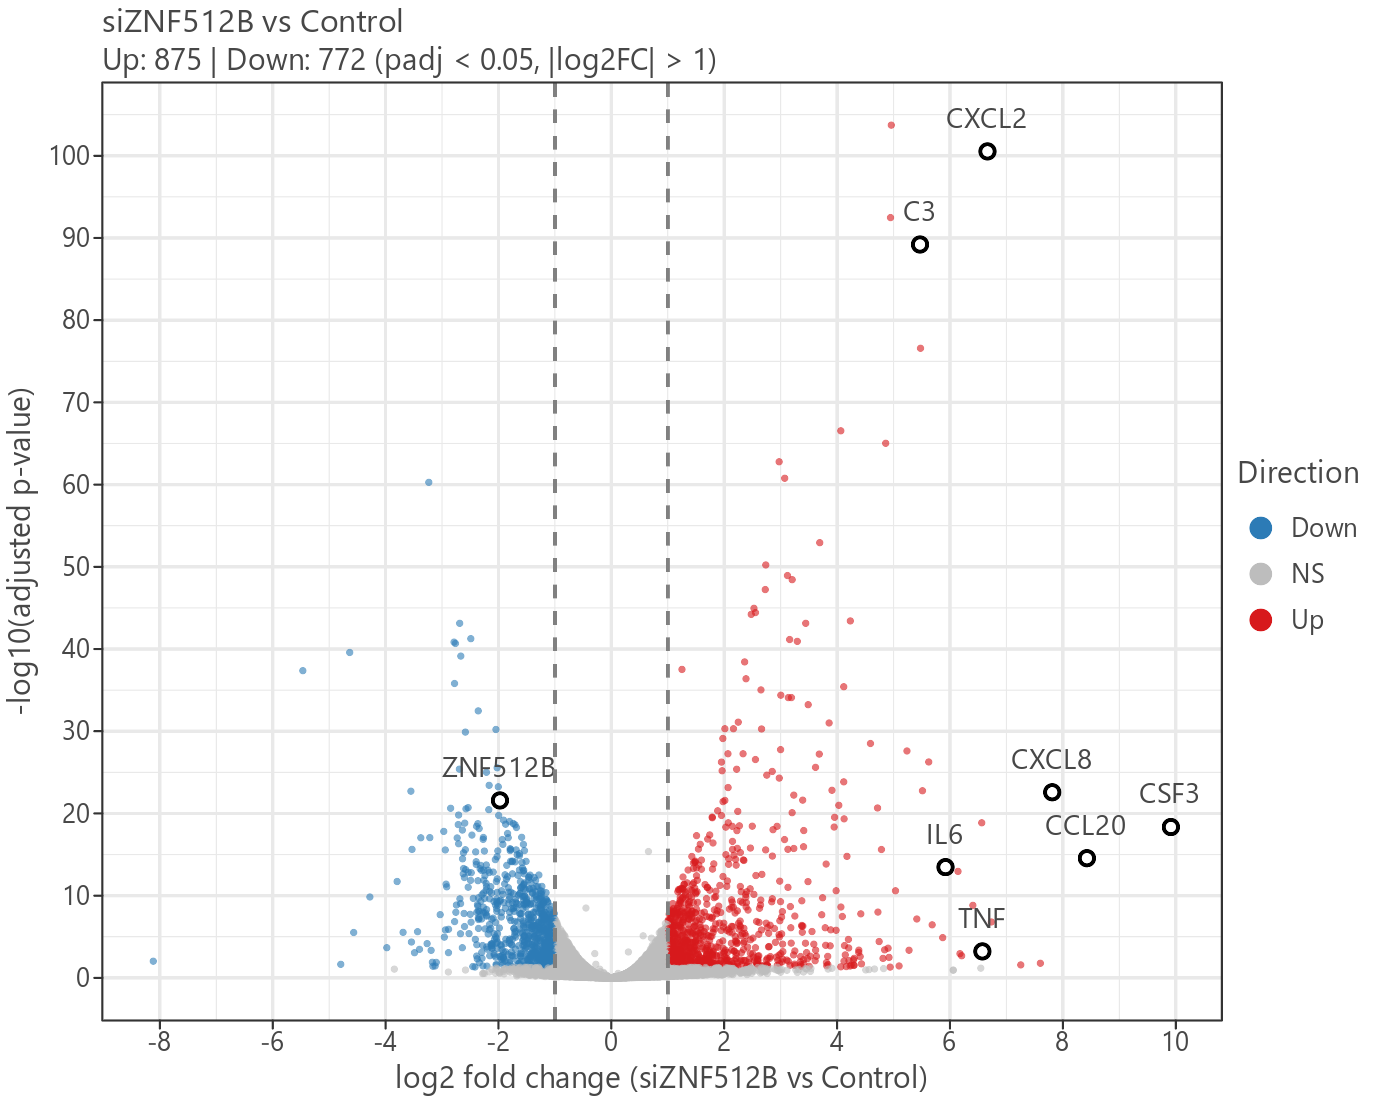

In [99]:
from IPython.display import Image
Image(filename="output_data/gsea_results/siZNF512B_volcano_plot_plot.png")

## GSEA: Hallmarks

Here, I will do GSEA analysis using the Hallmark gene sets. I will use the GSEApy library:

In [69]:
import gseapy as gp

In [70]:
gp.__version__

'1.1.11'

In [71]:
results_ranked = deseq2_results.sort_values("log2FoldChange", ascending=False)
results_ranked

,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
gene_symbol,,,,,,
CSF3,504.015533,9.913955,1.048773,9.452912,3.295335e-21,4.510490e-19
CCL20,886.863794,8.425784,0.998180,8.441147,3.142392e-17,2.784559e-15
CXCL8,50953.639684,7.811224,0.746593,10.462492,1.284326e-25,2.660638e-23
GPR18,18.664188,7.601373,2.546351,2.985203,2.833904e-03,1.670495e-02
NDNF,14.676279,7.254416,2.583928,2.807515,4.992542e-03,2.655644e-02
...,...,...,...,...,...,...
RIPOR3-AS1,35.073456,-4.564825,0.871158,-5.239953,1.606173e-07,3.028615e-06
RGCC,343.341326,-4.635424,0.336946,-13.757158,4.613053e-43,2.619189e-40
WNT16,233.746908,-4.794003,1.671005,-2.868934,4.118580e-03,2.255120e-02


In [72]:
results_ranked_2 = results_ranked["log2FoldChange"]
results_ranked_2.index

Index(['CSF3', 'CCL20', 'CXCL8', 'GPR18', 'NDNF', 'CXCL6', 'CXCL2', 'TNF',
       'ELF3', 'SAA2',
       ...
       'INSC', 'ITGA8', 'FANCD2P2', 'DRD1', 'GRPR', 'RIPOR3-AS1', 'RGCC',
       'WNT16', 'TOX', 'TACR1'],
      dtype='object', name='gene_symbol', length=15330)

In [73]:
results_ranked_2.shape

(15330,)

In [74]:
HALLMARK_GSEA = gp.prerank(
    rnk = results_ranked_2,    
    gene_sets = "MSigDB_Hallmark_2020",
    method = "multilevel",            
    permutation_num = 10000,                    
    threads = 4,
    min_size = 5,
    max_size = 1000,
    seed = 6,
    outdir = None
)

2026-09-30 21:23:05,699 [WARNING] Duplicated values found in preranked stats: 0.07% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


In [75]:
df_HALLMARK_GSEA = HALLMARK_GSEA.res2d
df_HALLMARK_GSEA.head(30)

,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes
0,prerank,E2F Targets,-0.728904,-3.146364,0.0,0.0,0.0,110/200,14.91%,CDC20;PRPS1;TK1;TOP2A;PLK4;CDCA8;BIRC5;MKI67;K...
1,prerank,G2-M Checkpoint,-0.70415,-3.020876,0.0,0.0,0.0,96/198,12.27%,GINS2;CENPA;CDC20;NEK2;TOP2A;PLK4;POLQ;BIRC5;M...
2,prerank,TNF-alpha Signaling via NF-kB,0.688349,2.454518,0.0,0.0,0.0,73/192,9.31%,CCL20;CXCL6;CXCL2;TNF;IL1B;IL6;IL1A;CXCL1;G0S2...
3,prerank,Inflammatory Response,0.685906,2.386999,0.0,0.0,0.0,77/151,13.91%,CSF3;CCL20;CXCL8;CXCL6;IL1B;IL6;IL1A;CCL7;TNFS...
4,prerank,KRAS Signaling Up,0.636006,2.220562,0.0,0.0,0.0,57/154,9.75%,CCL20;IL1B;G0S2;CSF2;PTGS2;MMP9;IL33;HSD11B1;A...
5,prerank,IL-6/JAK/STAT3 Signaling,0.701412,2.206715,0.0,0.0,0.0,21/68,9.82%,TNF;IL1B;IL6;CXCL1;CCL7;CXCL3;CSF2;CNTFR;EBI3;...
6,prerank,Mitotic Spindle,-0.514796,-2.190099,0.0,0.0,0.0,75/196,20.11%,NEK2;TOP2A;BIRC5;CCNB2;KIF2C;CENPF;TTK;CENPE;P...
7,prerank,Myc Targets V1,-0.506199,-2.165188,0.0,0.0,0.0,109/198,34.51%,CDC20;MCM5;CCNA2;CDC45;MCM6;MCM2;MCM4;MAD2L1;T...
8,prerank,Allograft Rejection,0.594395,2.018721,0.0,0.0,0.0,33/122,10.42%,TNF;IL1B;IL6;CCL7;MMP9;CCL2;ICAM1;CTSS;CD1D;IL...
9,prerank,Coagulation,0.607381,2.003552,0.0,0.0,0.0,41/99,13.75%,C3;MMP9;PECAM1;OLR1;COMP;KLKB1;CFB;THBD;TFPI2;...


In [76]:
os.makedirs("output_data/gsea_results", exist_ok=True)

In [77]:
df_HALLMARK_GSEA.to_csv("output_data/gsea_results/gsea_hallmark_results.csv")

In [78]:
conditions = [
    (df_HALLMARK_GSEA['FDR q-val'] < 0.05) & (df_HALLMARK_GSEA['NES'] > 0),
    (df_HALLMARK_GSEA['FDR q-val'] < 0.05) & (df_HALLMARK_GSEA['NES'] < 0)
]
choices = ['Up', 'Down']

df_HALLMARK_GSEA['change'] = np.select(conditions, choices, default='No Change')
df_HALLMARK_GSEA.head(10)

,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes,change
0,prerank,E2F Targets,-0.728904,-3.146364,0.0,0.0,0.0,110/200,14.91%,CDC20;PRPS1;TK1;TOP2A;PLK4;CDCA8;BIRC5;MKI67;K...,Down
1,prerank,G2-M Checkpoint,-0.70415,-3.020876,0.0,0.0,0.0,96/198,12.27%,GINS2;CENPA;CDC20;NEK2;TOP2A;PLK4;POLQ;BIRC5;M...,Down
2,prerank,TNF-alpha Signaling via NF-kB,0.688349,2.454518,0.0,0.0,0.0,73/192,9.31%,CCL20;CXCL6;CXCL2;TNF;IL1B;IL6;IL1A;CXCL1;G0S2...,Up
3,prerank,Inflammatory Response,0.685906,2.386999,0.0,0.0,0.0,77/151,13.91%,CSF3;CCL20;CXCL8;CXCL6;IL1B;IL6;IL1A;CCL7;TNFS...,Up
4,prerank,KRAS Signaling Up,0.636006,2.220562,0.0,0.0,0.0,57/154,9.75%,CCL20;IL1B;G0S2;CSF2;PTGS2;MMP9;IL33;HSD11B1;A...,Up
5,prerank,IL-6/JAK/STAT3 Signaling,0.701412,2.206715,0.0,0.0,0.0,21/68,9.82%,TNF;IL1B;IL6;CXCL1;CCL7;CXCL3;CSF2;CNTFR;EBI3;...,Up
6,prerank,Mitotic Spindle,-0.514796,-2.190099,0.0,0.0,0.0,75/196,20.11%,NEK2;TOP2A;BIRC5;CCNB2;KIF2C;CENPF;TTK;CENPE;P...,Down
7,prerank,Myc Targets V1,-0.506199,-2.165188,0.0,0.0,0.0,109/198,34.51%,CDC20;MCM5;CCNA2;CDC45;MCM6;MCM2;MCM4;MAD2L1;T...,Down
8,prerank,Allograft Rejection,0.594395,2.018721,0.0,0.0,0.0,33/122,10.42%,TNF;IL1B;IL6;CCL7;MMP9;CCL2;ICAM1;CTSS;CD1D;IL...,Up
9,prerank,Coagulation,0.607381,2.003552,0.0,0.0,0.0,41/99,13.75%,C3;MMP9;PECAM1;OLR1;COMP;KLKB1;CFB;THBD;TFPI2;...,Up


In [79]:
df_HALLMARK_GSEA["padjust"] = df_HALLMARK_GSEA["FDR q-val"].replace(0, 0.0001)
df_HALLMARK_GSEA.head(10)

,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes,change,padjust
0,prerank,E2F Targets,-0.728904,-3.146364,0.0,0.0,0.0,110/200,14.91%,CDC20;PRPS1;TK1;TOP2A;PLK4;CDCA8;BIRC5;MKI67;K...,Down,0.0001
1,prerank,G2-M Checkpoint,-0.70415,-3.020876,0.0,0.0,0.0,96/198,12.27%,GINS2;CENPA;CDC20;NEK2;TOP2A;PLK4;POLQ;BIRC5;M...,Down,0.0001
2,prerank,TNF-alpha Signaling via NF-kB,0.688349,2.454518,0.0,0.0,0.0,73/192,9.31%,CCL20;CXCL6;CXCL2;TNF;IL1B;IL6;IL1A;CXCL1;G0S2...,Up,0.0001
3,prerank,Inflammatory Response,0.685906,2.386999,0.0,0.0,0.0,77/151,13.91%,CSF3;CCL20;CXCL8;CXCL6;IL1B;IL6;IL1A;CCL7;TNFS...,Up,0.0001
4,prerank,KRAS Signaling Up,0.636006,2.220562,0.0,0.0,0.0,57/154,9.75%,CCL20;IL1B;G0S2;CSF2;PTGS2;MMP9;IL33;HSD11B1;A...,Up,0.0001
5,prerank,IL-6/JAK/STAT3 Signaling,0.701412,2.206715,0.0,0.0,0.0,21/68,9.82%,TNF;IL1B;IL6;CXCL1;CCL7;CXCL3;CSF2;CNTFR;EBI3;...,Up,0.0001
6,prerank,Mitotic Spindle,-0.514796,-2.190099,0.0,0.0,0.0,75/196,20.11%,NEK2;TOP2A;BIRC5;CCNB2;KIF2C;CENPF;TTK;CENPE;P...,Down,0.0001
7,prerank,Myc Targets V1,-0.506199,-2.165188,0.0,0.0,0.0,109/198,34.51%,CDC20;MCM5;CCNA2;CDC45;MCM6;MCM2;MCM4;MAD2L1;T...,Down,0.0001
8,prerank,Allograft Rejection,0.594395,2.018721,0.0,0.0,0.0,33/122,10.42%,TNF;IL1B;IL6;CCL7;MMP9;CCL2;ICAM1;CTSS;CD1D;IL...,Up,0.0001
9,prerank,Coagulation,0.607381,2.003552,0.0,0.0,0.0,41/99,13.75%,C3;MMP9;PECAM1;OLR1;COMP;KLKB1;CFB;THBD;TFPI2;...,Up,0.0001


In [80]:
from lets_plot import *
LetsPlot.setup_html()

In [81]:
df_HALLMARK_GSEA_signif = df_HALLMARK_GSEA.loc[df_HALLMARK_GSEA["padjust"] < 0.05]
df_HALLMARK_GSEA_signif = df_HALLMARK_GSEA_signif.sort_values("NES", ascending=True)
df_HALLMARK_GSEA_signif["NES_Dummy"] = 0
df_HALLMARK_GSEA_signif["log10padj"] = -np.log10(df_HALLMARK_GSEA_signif["padjust"])
df_HALLMARK_GSEA_signif

,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes,change,padjust,NES_Dummy,log10padj
0,prerank,E2F Targets,-0.728904,-3.146364,0.0,0.0,0.0,110/200,14.91%,CDC20;PRPS1;TK1;TOP2A;PLK4;CDCA8;BIRC5;MKI67;K...,Down,0.000100,0,4.000000
1,prerank,G2-M Checkpoint,-0.70415,-3.020876,0.0,0.0,0.0,96/198,12.27%,GINS2;CENPA;CDC20;NEK2;TOP2A;PLK4;POLQ;BIRC5;M...,Down,0.000100,0,4.000000
6,prerank,Mitotic Spindle,-0.514796,-2.190099,0.0,0.0,0.0,75/196,20.11%,NEK2;TOP2A;BIRC5;CCNB2;KIF2C;CENPF;TTK;CENPE;P...,Down,0.000100,0,4.000000
7,prerank,Myc Targets V1,-0.506199,-2.165188,0.0,0.0,0.0,109/198,34.51%,CDC20;MCM5;CCNA2;CDC45;MCM6;MCM2;MCM4;MAD2L1;T...,Down,0.000100,0,4.000000
10,prerank,Myc Targets V2,-0.558265,-1.974444,0.00035,0.00036,0.0009,23/57,24.79%,PLK4;PLK1;TMEM97;MCM5;MCM4;UTP20;TCOF1;PPRC1;W...,Down,0.000360,0,3.444280
13,prerank,UV Response Dn,-0.414193,-1.700466,0.0,0.005826,0.017403,42/141,15.66%,KIT;CAV1;PLCB4;DBP;F3;PPARG;DAB2;LPAR1;GCNT1;B...,Down,0.005826,0,2.234666
16,prerank,mTORC1 Signaling,-0.34653,-1.488353,0.000696,0.037407,0.121624,60/195,20.14%,DHCR24;PLK1;TMEM97;BUB1;RRM2;AURKA;FGL2;MCM2;M...,Down,0.037407,0,1.427048
20,prerank,Cholesterol Homeostasis,-0.392331,-1.443953,0.018059,0.045714,0.165433,22/69,13.71%,TMEM97;MVK;PPARG;ACAT2;PCYT2;ETHE1;FABP5;CBS;S...,Down,0.045714,0,1.339954
22,prerank,Estrogen Response Late,-0.346568,-1.431559,0.003335,0.045117,0.182436,55/147,19.36%,GINS2;CDC20;TOP2A;PLK4;KIF20A;PRSS23;CAV1;ZFP3...,Down,0.045117,0,1.345658
23,prerank,Spermatogenesis,-0.378155,-1.414978,0.023771,0.047396,0.208042,23/77,14.68%,NEK2;CCNB2;CFTR;KIF2C;TTK;BUB1;CDKN3;NCAPH;CDK...,Down,0.047396,0,1.324255


In [82]:
from lets_plot import ggsave, ggsize

plot = (
    ggplot(df_HALLMARK_GSEA_signif, aes(x="NES", y="Term"))
    + geom_segment(aes(xend="NES", yend="Term", x="NES_Dummy"))
    + geom_point(aes(fill="change", size="log10padj"), shape=21)
    + scale_fill_manual(values=["blue", "red"], name="Direction")
    + scale_size_area(name="-log10(FDR)", max_size=3)
    + theme_bw()
    + scale_y_discrete(expand=(0, 1))
    + theme(text=element_text(size=10))
    + xlim(-5, 4)
    + labs(x="NES", y="Gene Sets", title="siZNF512B vs Control", subtitle="Hallmark Gene Sets")
    + geom_vline(xintercept=0, linetype="dotted")
    + ggsize(600, 500)
)

ggsave(plot, "output_data/gsea_results/hallmark_gsea_plot.png", path=".")

'C:\\Users\\cdsou\\Desktop\\GSE206071\\output_data\\gsea_results\\hallmark_gsea_plot.png'

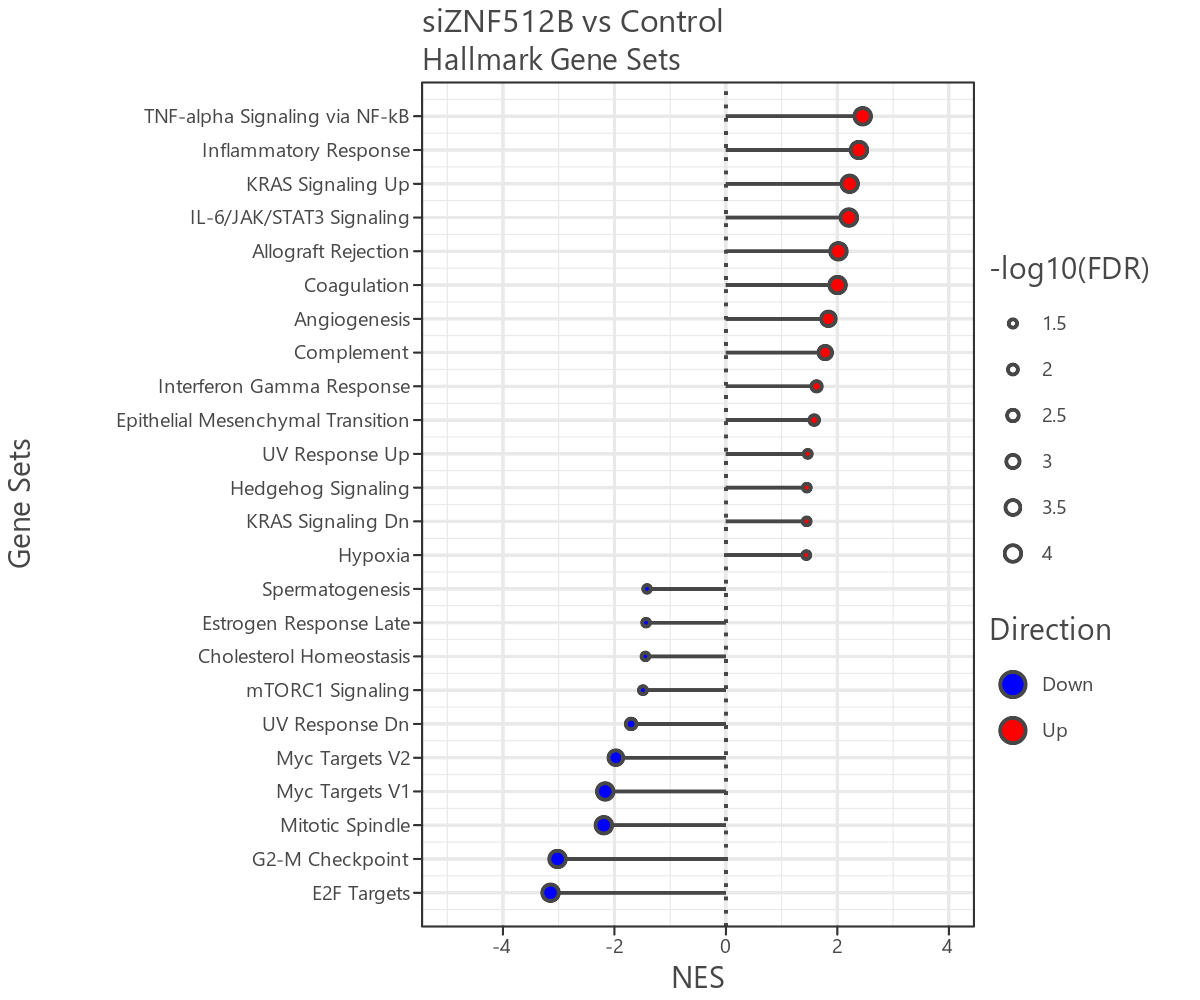

In [83]:
from IPython.display import Image
Image(filename="output_data/gsea_results/hallmark_gsea_plot.png")

## GSEA: SenMayo

Next, I performed GSEA using the SenMayo gene set, which is commonly used as a proxy for senescence-associated gene expression. To use custom gene sets, we need to create a dictionary:

In [84]:
senmayo_df = pd.read_csv("input_data/signatures/senmayo_gene_set.txt", sep = "\t", index_col=0)
senmayo_df

,gene_symbol
gene_set,
SenMayo,ACVR1B
SenMayo,ANG
SenMayo,ANGPT1
SenMayo,ANGPTL4
SenMayo,AREG
...,...
SenMayo,VEGFA
SenMayo,VEGFC
SenMayo,VGF


In [85]:
senmayo_gene_set = {'SenMayo': senmayo_df["gene_symbol"]}
senmayo_gene_set

{'SenMayo': gene_set
 SenMayo     ACVR1B
 SenMayo        ANG
 SenMayo     ANGPT1
 SenMayo    ANGPTL4
 SenMayo       AREG
             ...   
 SenMayo      VEGFA
 SenMayo      VEGFC
 SenMayo        VGF
 SenMayo      WNT16
 SenMayo       WNT2
 Name: gene_symbol, Length: 124, dtype: object}

In [86]:
SENMAYO_GSEA = gp.prerank(
    rnk = results_ranked_2,    
    gene_sets = senmayo_gene_set,
    method = "multilevel",            
    permutation_num = 10000,                    
    threads = 4,
    min_size = 5,
    max_size = 1000,
    seed = 6,
    outdir = None
)

2026-09-30 21:25:08,638 [WARNING] Duplicated values found in preranked stats: 0.07% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


In [87]:
df_SENMAYO_GSEA = SENMAYO_GSEA.res2d
df_SENMAYO_GSEA.head(30)

,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes
0,prerank,SenMayo,0.700293,2.317301,0.0,0.0,0.0,37/101,6.54%,CCL20;CXCL8;CXCL2;TNF;IL1B;IL6;IL1A;CXCL1;CCL7...


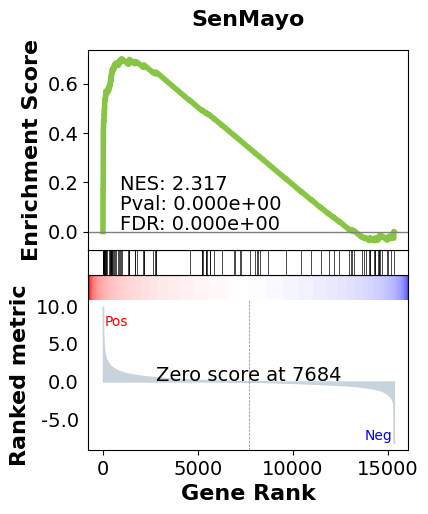

In [88]:
terms = SENMAYO_GSEA.res2d.Term
axs = SENMAYO_GSEA.plot(terms=terms[0])

In [100]:
axs = SENMAYO_GSEA.plot(terms=terms[0], ofname="output_data/gsea_results/senmayo_gsea_plot.png")

## Conclusions

ZNF512B knockdown in primary fibroblasts leads to a robust upregulation of senescence and inflammation-associated signatures as described in the original paper.